# Regresión lineal I

**Sesión 09 · Regresión I**

En las sesiones anteriores hemos descrito datos (sesión 06), hemos cuantificado la incertidumbre de lo que observamos (sesión 07) y hemos actualizado creencias a partir de datos (sesión 08). Hoy construimos nuestro primer **modelo predictivo**: una **regresión lineal**.

El problema es **predecir el precio mediano de la vivienda** en los bloques censales de California a partir de las características de cada bloque (ingresos, edad de las viviendas, habitaciones, población, ubicación…), con datos del censo de 1990. Ajustaremos un modelo de mínimos cuadrados ordinarios (OLS), mediremos su calidad predictiva, veremos dónde se equivoca y abriremos la caja para entender cómo calcula cada predicción.

**Contenido**

1. Carga y exploración de los datos
2. Limpieza de los datos
3. División en entrenamiento y test
4. Regresión lineal simple: una variable cada vez
5. Regresión lineal múltiple
6. Métricas de evaluación
7. Diagnóstico de residuos
8. Error por rango de precio
9. Abrir la caja: cómo calcula el modelo una predicción
10. Regresión polinomial: ¿mejora el modelo?
11. Conclusiones
12. Ejercicio extra: el hielo marino del Ártico

## 1. Carga y exploración de los datos

Usamos el conjunto *California Housing*, incluido en scikit-learn: un registro por **bloque censal** de California en el censo de 1990. La **variable objetivo** (*target*) es `MedHouseVal`, el precio mediano de la vivienda del bloque, y las otras ocho columnas son las **variables explicativas** (*features*).

La primera vez que lo cargas, scikit-learn lo descarga de internet (menos de 1 MB) y lo guarda en la carpeta `~/scikit_learn_data`. A partir de ahí funciona sin conexión.

In [31]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

plt.style.use('ggplot')
pd.set_option('display.float_format', '{:.4f}'.format)
SEED = 42            # semilla fija: la división en entrenamiento y test es reproducible
DATOS = Path('files')

# Colores del curso
C1 = '#2a78d6'       # azul: serie principal
C2 = '#eb6834'       # naranja: contraste y residuos
C3 = '#898781'       # gris: referencia
CTEXT = '#52514e'    # texto de los ejes

Antes de modelar, inspeccionamos el conjunto de datos para entender su estructura, detectar valores ausentes y duplicados, y ver la distribución de la variable objetivo.

In [32]:
raw = fetch_california_housing(as_frame=True)
df_raw = raw.frame.copy()
TARGET = 'MedHouseVal'

print('=== Dimensiones ===')
print(f'{df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas')

print('\n=== Variables ===')
descripciones = [
    'Ingreso mediano del bloque (decenas de miles USD)',
    'Edad mediana de las viviendas (años)',
    'Media de habitaciones por hogar',
    'Media de dormitorios por hogar',
    'Población del bloque',
    'Media de personas por hogar',
    'Latitud del bloque censal',
    'Longitud del bloque censal',
    'Precio mediano de la vivienda (100 000 USD): variable objetivo',
]
for nombre, desc in zip(raw.feature_names + [TARGET], descripciones):
    print(f'  {nombre:<12} {desc}')

=== Dimensiones ===
20,640 filas x 9 columnas

=== Variables ===
  MedInc       Ingreso mediano del bloque (decenas de miles USD)
  HouseAge     Edad mediana de las viviendas (años)
  AveRooms     Media de habitaciones por hogar
  AveBedrms    Media de dormitorios por hogar
  Population   Población del bloque
  AveOccup     Media de personas por hogar
  Latitude     Latitud del bloque censal
  Longitude    Longitud del bloque censal
  MedHouseVal  Precio mediano de la vivienda (100 000 USD): variable objetivo


In [33]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0000,3.8700,1.9000,0.5000,2.5600,3.5300,4.7400,15.0000
HouseAge,20640.0000,28.6400,12.5900,1.0000,18.0000,29.0000,37.0000,52.0000
AveRooms,20640.0000,5.4300,2.4700,0.8500,4.4400,5.2300,6.0500,141.9100
AveBedrms,20640.0000,1.1000,0.4700,0.3300,1.0100,1.0500,1.1000,34.0700
Population,20640.0000,1425.4800,1132.4600,3.0000,787.0000,1166.0000,1725.0000,35682.0000
AveOccup,20640.0000,3.0700,10.3900,0.6900,2.4300,2.8200,3.2800,1243.3300
Latitude,20640.0000,35.6300,2.1400,32.5400,33.9300,34.2600,37.7100,41.9500
Longitude,20640.0000,-119.5700,2.0000,-124.3500,-121.8000,-118.4900,-118.0100,-114.3100
MedHouseVal,20640.0000,2.0700,1.1500,0.1500,1.2000,1.8000,2.6500,5.0000


In [34]:
print('=== Valores ausentes ===')
ausentes = df_raw.isnull().sum()
if ausentes.any():
    print(ausentes[ausentes > 0])
else:
    print('Ninguno: el conjunto está completo')

print('\n=== Filas duplicadas ===')
n_dup = df_raw.duplicated().sum()
print(f'{n_dup} filas duplicadas' if n_dup > 0 else 'Ninguna')

=== Valores ausentes ===
Ninguno: el conjunto está completo

=== Filas duplicadas ===
Ninguna


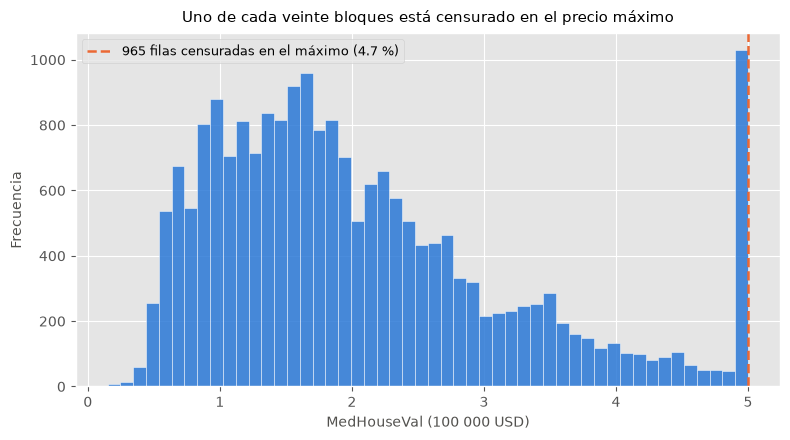

In [35]:
censurados = df_raw[df_raw[TARGET] == df_raw[TARGET].max()]
pct = len(censurados) / len(df_raw) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df_raw[TARGET], bins=50, color=C1, alpha=0.85, edgecolor='white', linewidth=0.4)
ax.axvline(df_raw[TARGET].max(), color=C2, linewidth=1.8, linestyle='--',
           label=f'{len(censurados):,} filas censuradas en el máximo ({pct:.1f} %)')
ax.set_xlabel('MedHouseVal (100 000 USD)', fontsize=10, color=CTEXT)
ax.set_ylabel('Frecuencia', fontsize=10, color=CTEXT)
ax.set_title('Uno de cada veinte bloques está censurado en el precio máximo', fontsize=11, pad=8)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Observaciones**

- El conjunto tiene **20.640 bloques censales** y **9 columnas** (8 variables explicativas y la variable objetivo).
- **No hay valores ausentes ni duplicados**: un conjunto excepcionalmente limpio para ser datos reales.
- El histograma de la variable objetivo tiene un **pico artificial en el máximo**: todos los bloques con un precio mediano superior a 500.000 USD se recodificaron con el mismo valor (5,00001 en los datos). Es una **censura** de la variable objetivo y afecta a 965 bloques, el 4,7 %.
- La distribución es asimétrica a la derecha (cola de precios altos), lo que anticipa que el modelo lineal tendrá dificultades en ese rango.
- `describe()` muestra máximos inverosímiles en `AveRooms` (142 habitaciones por hogar) y `AveOccup` (1.243 personas por hogar). Los exploramos en la sección siguiente.

## 2. Limpieza de los datos

Tomamos dos decisiones de limpieza. Para cada una valoramos los pros y los contras antes de aplicarla.

### 2.1 Censura de la variable objetivo: ¿eliminamos los bloques con el precio máximo?

**El problema:** el valor máximo no es un precio real, sino un tope. Un modelo que aprenda con estos bloques verá que bloques con características muy diversas tienen el mismo precio, y eso introduce ruido en los coeficientes.

| | Eliminar los bloques censurados | Conservarlos |
|---|---|---|
| **A favor** | El modelo aprende solo de precios reales; coeficientes menos sesgados | Usamos todos los datos; el modelo cubre todo el dominio |
| **En contra** | Perdemos casi el 5 % de los datos; el modelo no sirve para precios > 500.000 USD | El modelo aprende una relación ficticia en el límite superior |

**Decisión en este notebook: conservamos los bloques censurados.** Es una decisión pedagógica: en las secciones de residuos y de error por rango de precio veremos el efecto concreto de la censura sobre el modelo.

En un proyecto real habría que comprobar si los bloques censurados son ruido aleatorio (sus características medias serían iguales a las del resto) o son sistemáticamente distintos, y decidir en consecuencia. Eliminarlos mejoraría el modelo en el dominio que queda representado (viviendas de precio bajo y medio), pero el modelo fallaría con las viviendas caras. El coste es reducir el **dominio de validez** del modelo, y esa limitación hay que documentarla al comunicar los resultados.

**Ejercicio 1**

Haz la comprobación que propone el párrafo anterior: compara la media de cada variable explicativa en los bloques censurados y en el resto. ¿Te parecen ruido aleatorio o un grupo distinto?

Pista: `df_raw.groupby(df_raw[TARGET] == df_raw[TARGET].max()).mean()`.

In [36]:
# Escribe aquí tu solución

_Tu respuesta:_

### 2.2 Valores atípicos en las variables de cociente (`AveRooms`, `AveOccup`)

Estas variables se calculan dividiendo dos recuentos del bloque censal:

| Variable | Fórmula | Significado |
|---|---|---|
| `AveRooms` | habitaciones / hogares | Habitaciones medias por hogar |
| `AveBedrms` | dormitorios / hogares | Dormitorios medios por hogar |
| `AveOccup` | personas / hogares | Personas medias por hogar |

**El problema:** cuando el denominador (el número de hogares) es muy pequeño, como en bloques de hoteles, residencias o zonas industriales, el cociente se dispara a valores inverosímiles: 100 habitaciones o 50 personas por hogar. No son errores de medición, sino **artefactos** de un denominador pequeño.

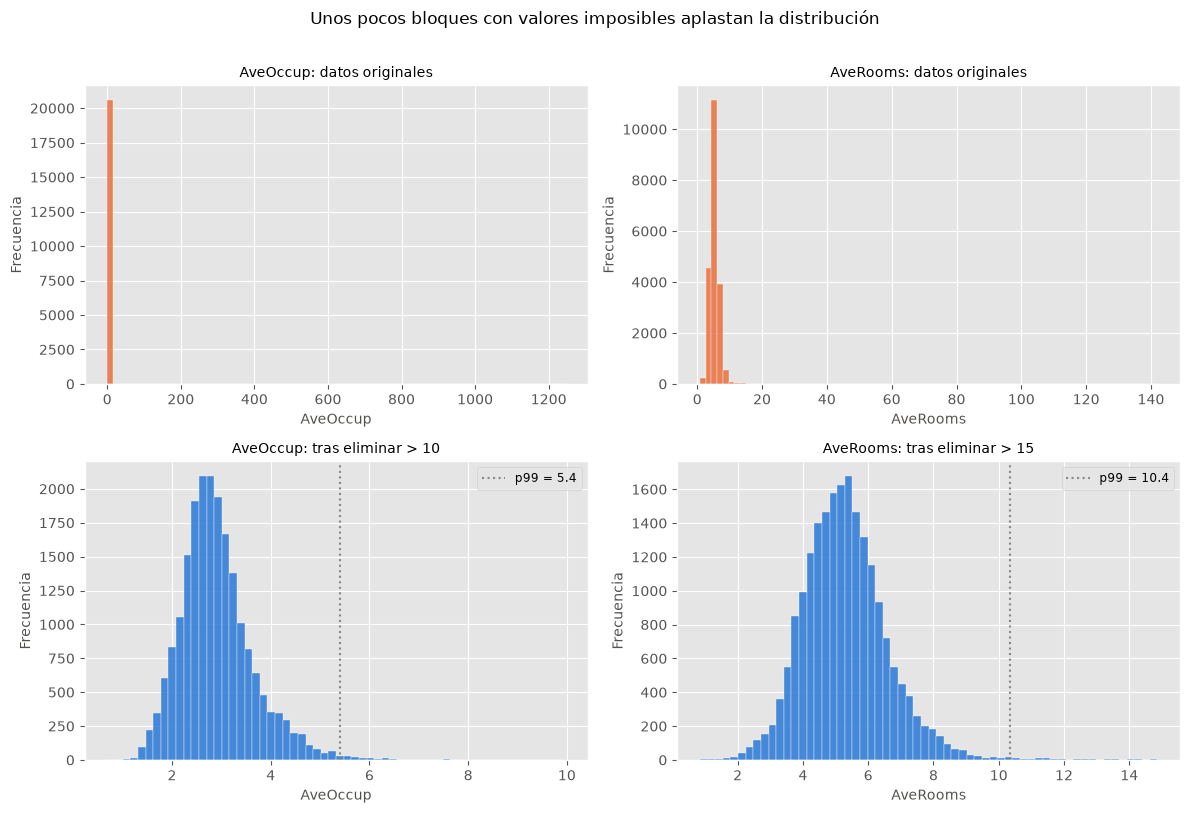

Estadísticos clave:
  AveOccup: máx=1243, p99=5.4, filas > 10: 37 (0.2 %)
  AveRooms: máx=142, p99=10.4, filas > 15: 109 (0.5 %)


In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

datos_cociente = [
    ('AveOccup', 10, df_raw['AveOccup'].quantile(0.99)),
    ('AveRooms', 15, df_raw['AveRooms'].quantile(0.99)),
]

for col, (var, umbral, p99_val) in enumerate(datos_cociente):
    df_clean_var = df_raw[df_raw[var] <= umbral]

    # Fila 0: distribución original (con valores atípicos)
    ax = axes[0, col]
    ax.hist(df_raw[var], bins=80, color=C2, alpha=0.80, edgecolor='white', linewidth=0.3)
    ax.set_xlabel(var, fontsize=10, color=CTEXT)
    ax.set_ylabel('Frecuencia', fontsize=10, color=CTEXT)
    ax.set_title(f'{var}: datos originales', fontsize=10, pad=6)

    # Fila 1: distribución tras la limpieza
    ax = axes[1, col]
    ax.hist(df_clean_var[var], bins=60, color=C1, alpha=0.85, edgecolor='white', linewidth=0.3)
    ax.axvline(p99_val, color=C3, linewidth=1.5, linestyle=':', label=f'p99 = {p99_val:.1f}')
    ax.set_xlabel(var, fontsize=10, color=CTEXT)
    ax.set_ylabel('Frecuencia', fontsize=10, color=CTEXT)
    ax.set_title(f'{var}: tras eliminar > {umbral}', fontsize=10, pad=6)
    ax.legend(fontsize=8.5)

plt.suptitle('Unos pocos bloques con valores imposibles aplastan la distribución', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

print('Estadísticos clave:')
for var, umbral in [('AveOccup', 10), ('AveRooms', 15)]:
    p99 = df_raw[var].quantile(0.99)
    n_out = (df_raw[var] > umbral).sum()
    print(f'  {var}: máx={df_raw[var].max():.0f}, p99={p99:.1f}, '
          f'filas > {umbral}: {n_out} ({n_out / len(df_raw) * 100:.1f} %)')

**Observaciones**

- **`AveOccup`:** la mayoría de los bloques tienen entre 2 y 4 personas por hogar, un valor normal en California. El percentil 99 es 5,4, así que el umbral de 10 es conservador: solo quita 37 bloques (0,2 %) con valores claramente imposibles.
- **`AveRooms`:** la mediana está en torno a 5 habitaciones por hogar y el percentil 99, en 10,4. Por encima de 15 hay 109 bloques (0,5 %), artefactos del mismo problema.
- Estos valores extremos **no son precios altos ni bajos**: son bloques atípicos por su tamaño. Incluirlos distorsionaría los coeficientes de `AveOccup` y `AveRooms`, porque el modelo intentaría aprender una señal que no existe.

**Decisión:** eliminamos los bloques con `AveOccup > 10` o `AveRooms > 15`.

In [38]:
# Partimos de los datos originales, SIN eliminar la censura (decisión pedagógica)
df = df_raw.copy()
print(f'Filas originales:                {len(df):,}')

n_cens = (df[TARGET] == df[TARGET].max()).sum()
print(f'Filas censuradas (conservadas):  {n_cens:,}')

# Limpieza: valores atípicos de los cocientes
df = df[df['AveOccup'] <= 10]
df = df[df['AveRooms'] <= 15]
n_elim = len(df_raw) - len(df)
print(f'Tras eliminar los atípicos:      {len(df):,}')
print(f'Filas eliminadas:                {n_elim:,} ({n_elim / len(df_raw) * 100:.1f} %)')

Filas originales:                20,640
Filas censuradas (conservadas):  965
Tras eliminar los atípicos:      20,495
Filas eliminadas:                145 (0.7 %)


**Observaciones**

- Conservamos los bloques censurados: en las secciones 7 y 8 veremos su efecto en los residuos y en el error.
- Eliminamos 145 bloques (0,7 %) por valores atípicos en los cocientes. Son pocos, pero con mucho peso potencial sobre los coeficientes.
- El conjunto resultante tiene **20.495 bloques censales** listos para modelar.

### 2.3 Exploración visual: cada variable frente a la variable objetivo

Con los datos ya limpios, dibujamos la relación de cada variable con el precio. Es el primer indicio de qué variables tienen señal predictiva y de si esa señal es lineal.

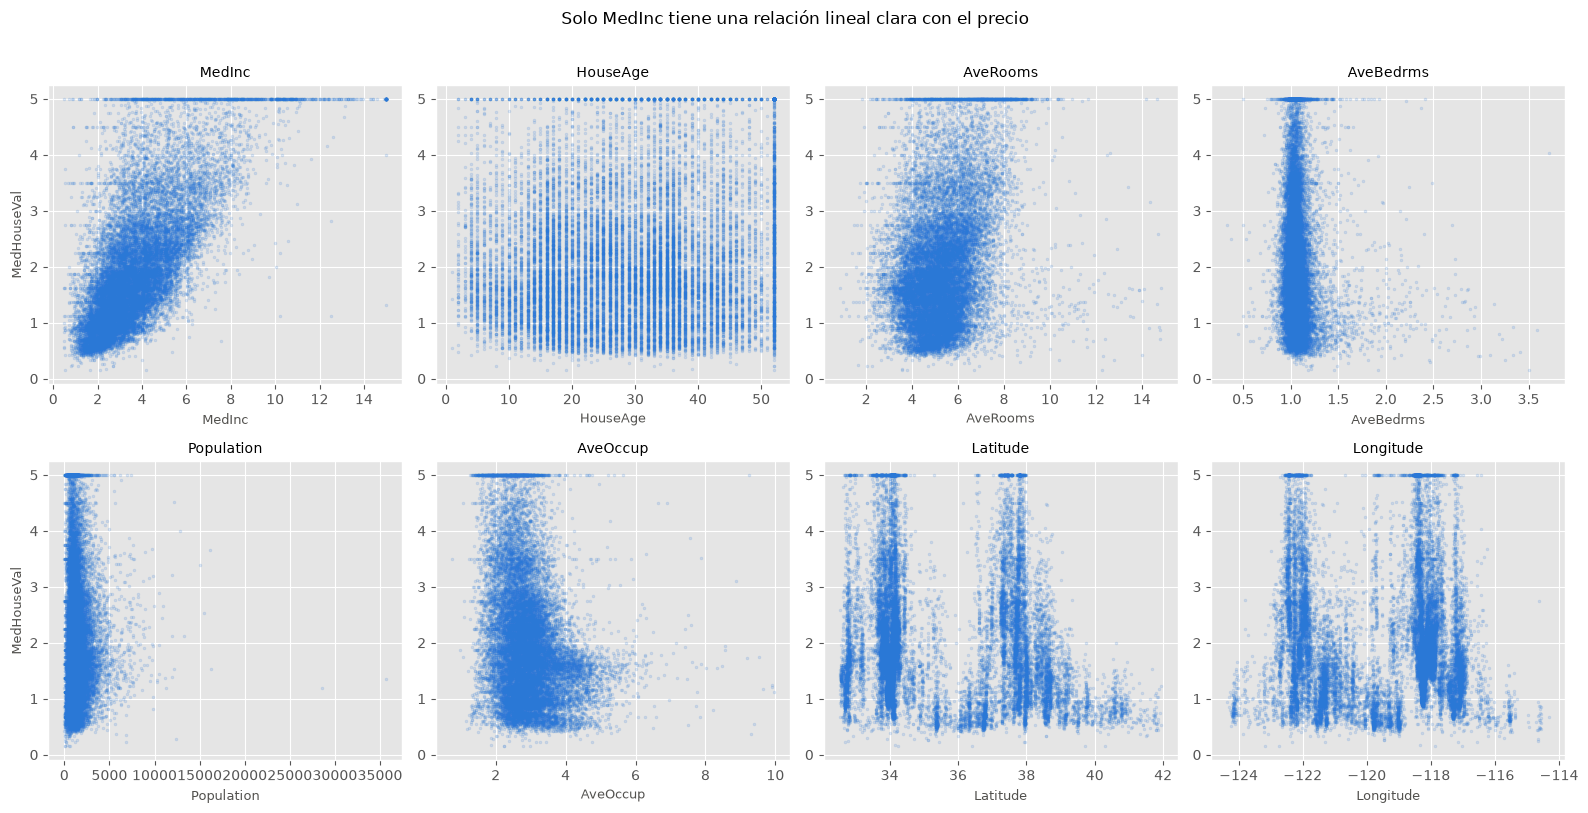

In [39]:
FEATURES = [c for c in df.columns if c != TARGET]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, feat in enumerate(FEATURES):
    ax = axes[i]
    ax.scatter(df[feat], df[TARGET], alpha=0.15, s=4, color=C1)
    ax.set_xlabel(feat, fontsize=9, color=CTEXT)
    ax.set_ylabel('MedHouseVal' if i % 4 == 0 else '', fontsize=9, color=CTEXT)
    ax.set_title(feat, fontsize=10)

plt.suptitle('Solo MedInc tiene una relación lineal clara con el precio', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

**Observaciones**

- **`MedInc`** es la variable con la relación más clara y positiva con el precio: a mayor ingreso mediano del bloque, mayor precio. La relación es aproximadamente lineal, con la parte alta cortada por la censura.
- **`HouseAge`** muestra poca señal: bloques de edades distintas tienen precios muy dispersos.
- **`AveRooms`** y **`AveBedrms`** muestran como mucho una tendencia leve. Tras la limpieza, los valores atípicos ya no aplastan el eje horizontal.
- **`Population`** no muestra ninguna tendencia; **`AveOccup`**, una tendencia negativa leve (más personas por hogar, precios algo más bajos).
- **`Latitude`** y **`Longitude`** tienen una estructura no lineal: los precios altos se concentran en dos zonas (el área de Los Ángeles y la de San Francisco), y una recta no puede capturar eso.

**Conclusión:** `MedInc` es la variable más informativa por sí sola. Las coordenadas tienen señal, pero no lineal. Lo cuantificamos en la sección 4.

## 3. División en entrenamiento y test

Dividimos los datos en un **80 % para entrenar** el modelo (conjunto de entrenamiento) y un **20 % para evaluarlo** (conjunto de test). El conjunto de test no se usa nunca durante el entrenamiento: simula datos futuros que el modelo no ha visto.

In [40]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

print(f'Entrenamiento: {X_train.shape[0]:,} filas')
print(f'Test:          {X_test.shape[0]:,} filas')
print(f'\nVariables ({len(FEATURES)}): {FEATURES}')

Entrenamiento: 16,396 filas
Test:          4,099 filas

Variables (8): ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


**Observaciones**

- `random_state=SEED` garantiza la **reproducibilidad**: con los mismos datos, la partición es siempre la misma.
- El reparto 80/20 es una convención habitual. Con 20.495 bloques, el conjunto de test tiene 4.099: suficientes para estimar las métricas con poca variabilidad.
- **Regla fundamental:** el conjunto de test no puede influir en ninguna decisión de modelado (qué variables usar, qué umbrales, qué hiperparámetros). Si se usa para decidir, deja de ser un test y pasa a ser parte del entrenamiento.

## 4. Regresión lineal simple: una variable cada vez

Antes de ajustar el modelo múltiple, ajustamos un modelo OLS independiente para cada variable. Así vemos qué poder predictivo tiene cada una **por sí sola**, y tenemos una referencia (*baseline*) para medir lo que gana el modelo múltiple.

### Modelo de regresión lineal simple

Con una única variable $x$, ajustamos un modelo que describe la relación entre $x$ e $y$:

$$\hat{y}_i = \beta_0 + \beta_1 x_{i}$$

donde $\beta_0$ es el intercepto (valor de $\hat{y}$ cuando $x = 0$) y $\beta_1$ es la pendiente (cambio en $\hat{y}$ por unidad de $x$).

**Mínimos cuadrados ordinarios** (OLS, *ordinary least squares*) estima los coeficientes minimizando la suma de cuadrados de los residuos:

$$\hat{\beta}_0, \hat{\beta}_1 = \arg\min_{\beta_0, \beta_1} \sum_{i=1}^{n} \left(y_i - \beta_0 - \beta_1 x_{i}\right)^2$$



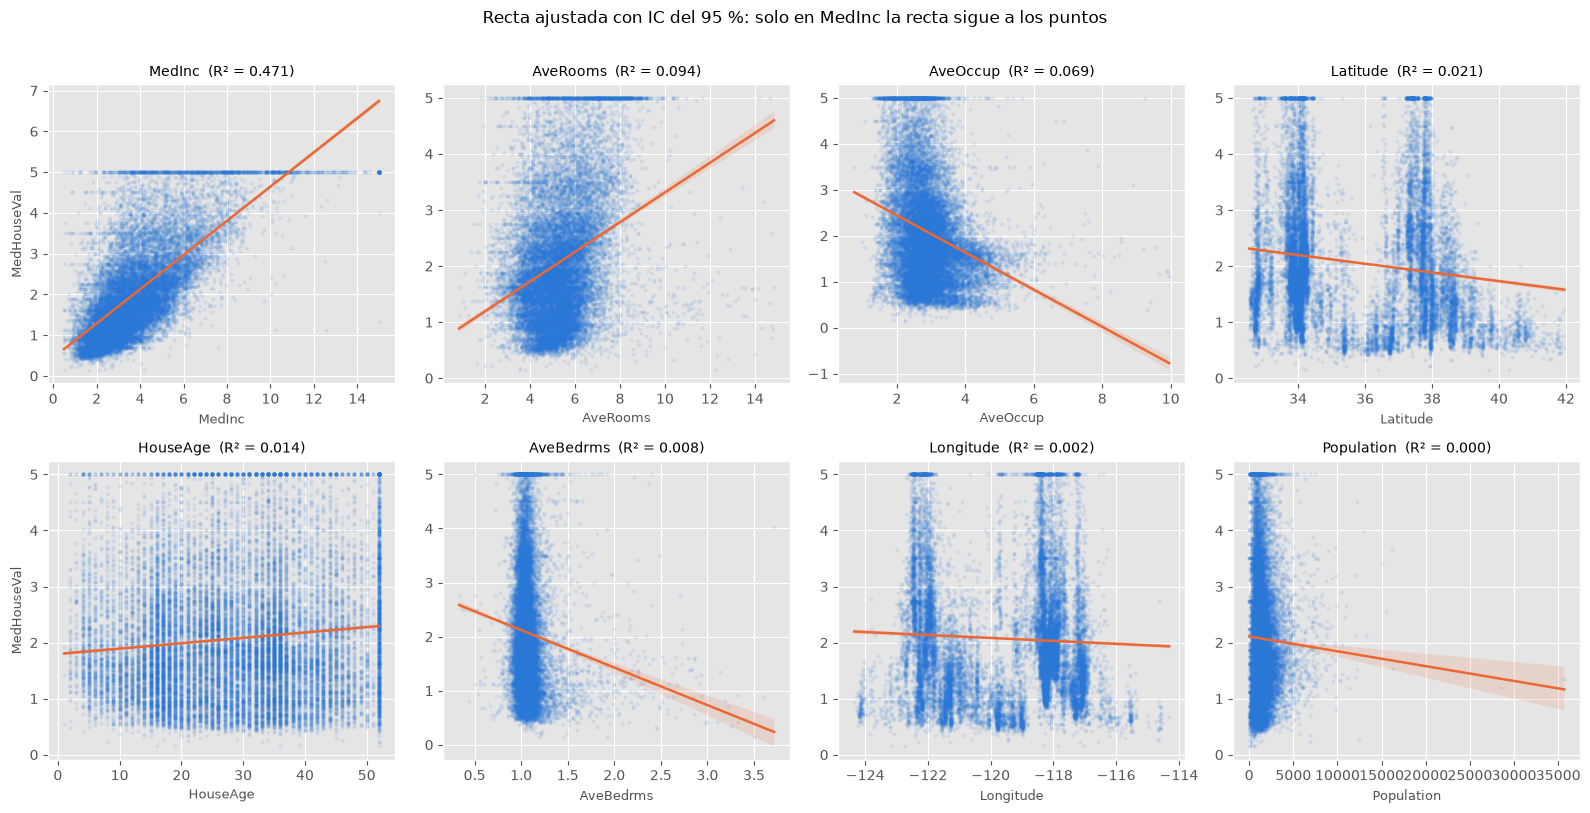

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, feat in enumerate(features_ord):
    ax = axes[i]
    sns.regplot(
        x=df[feat], y=df[TARGET], ax=ax,
        scatter_kws={'alpha': 0.08, 's': 4, 'color': C1},
        line_kws={'color': C2, 'linewidth': 1.8},
        ci=95,
    )
    r2_val = df_simples.loc[feat, 'R²_test']
    ax.set_xlabel(feat, fontsize=9, color=CTEXT)
    ax.set_ylabel('MedHouseVal' if i % 4 == 0 else '', fontsize=9, color=CTEXT)
    ax.set_title(f'{feat}  (R² = {r2_val:.3f})', fontsize=10)

plt.suptitle('Recta ajustada con IC del 95 %: solo en MedInc la recta sigue a los puntos', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

**Observaciones**

- **`MedInc`** tiene la recta con mayor pendiente y la banda de confianza más estrecha: es la relación lineal más consistente del conjunto. Los puntos siguen razonablemente la recta hasta ingresos de 8 o 10 (80.000–100.000 USD), donde la censura en el precio máximo forma una línea horizontal que rompe el patrón.
- **`Latitude`** y **`Longitude`**: rectas casi planas sobre nubes con dos zonas muy marcadas. Hay señal geográfica, pero una sola recta no captura las dos zonas de precios altos.
- **`HouseAge`** y **`Population`**: rectas casi planas, con muy poca señal lineal. La ligera inclinación de `Population` la marcan unos pocos bloques muy poblados.
- **`AveBedrms`**: la recta baja con claridad, pero su R² es de solo 0,008. La inclinación la deciden unos pocos bloques con muchos dormitorios por hogar, no la nube principal: **una pendiente visible no es lo mismo que una relación fuerte**.
- **`AveRooms`** y **`AveOccup`**: pendiente leve, positiva y negativa respectivamente, con mucha dispersión.
- `AveRooms` y `AveBedrms` están correlacionadas: en los datos originales, su correlación de Pearson es 0,85; tras la limpieza baja a 0,37, porque buena parte de esa correlación la creaban los bloques atípicos. La correlación entre variables explicativas (**multicolinealidad**) es uno de los temas de la sesión 10.

**Cómo leer la banda del IC del 95 %:** una banda estrecha indica que la posición de la recta está bien determinada por los datos. Una banda ancha indica que la recta podría inclinarse bastante más o menos y seguir siendo compatible con ellos. Con 20.000 puntos, casi todas las bandas son muy estrechas: **una recta bien determinada no es lo mismo que una recta útil** (fíjate en `Population`).

## 5. Métricas de evaluación

Evaluamos el modelo sobre el **conjunto de test**, con datos que no ha visto durante el entrenamiento.

| Métrica | Fórmula | Interpretación |
|---|---|---|
| **R²** | $1 - \dfrac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$ | Fracción de varianza explicada. 1.0 = perfecto; 0.0 = modelo nulo (predice siempre la media) |
| **MAE** | $\dfrac{1}{n}\sum_{i=1}^{n} \|y_i - \hat{y}_i\|$ | Error medio absoluto, en las mismas unidades que el target (100k USD) |



Calculamos ambas métricas sobre **train y test** para detectar si hay overfitting.

In [42]:
resultados_simples = []

for feat in FEATURES:
    m = LinearRegression()
    m.fit(X_train[[feat]], y_train)
    y_p_train = m.predict(X_train[[feat]])
    y_p_test = m.predict(X_test[[feat]])
    resultados_simples.append({
        'feature': feat,
        'R²_train': round(r2_score(y_train, y_p_train), 4),
        'R²_test': round(r2_score(y_test, y_p_test), 4),
        'MAE_train': round(mean_absolute_error(y_train, y_p_train), 4),
        'MAE_test': round(mean_absolute_error(y_test, y_p_test), 4),
    })

df_simples = (pd.DataFrame(resultados_simples)
              .sort_values('R²_test', ascending=False)
              .set_index('feature'))
df_simples

,R²_train,R²_test,MAE_train,MAE_test
feature,,,,
MedInc,0.4768,0.4715,0.6244,0.6296
AveRooms,0.0908,0.0937,0.8616,0.8564
AveOccup,0.0727,0.0686,0.8697,0.8679
Latitude,0.0204,0.0211,0.9049,0.9007
HouseAge,0.0102,0.0136,0.9090,0.9026
AveBedrms,0.0094,0.0083,0.9068,0.9037
Longitude,0.0021,0.0018,0.9109,0.9054
Population,0.0008,0.0000,0.9138,0.9088


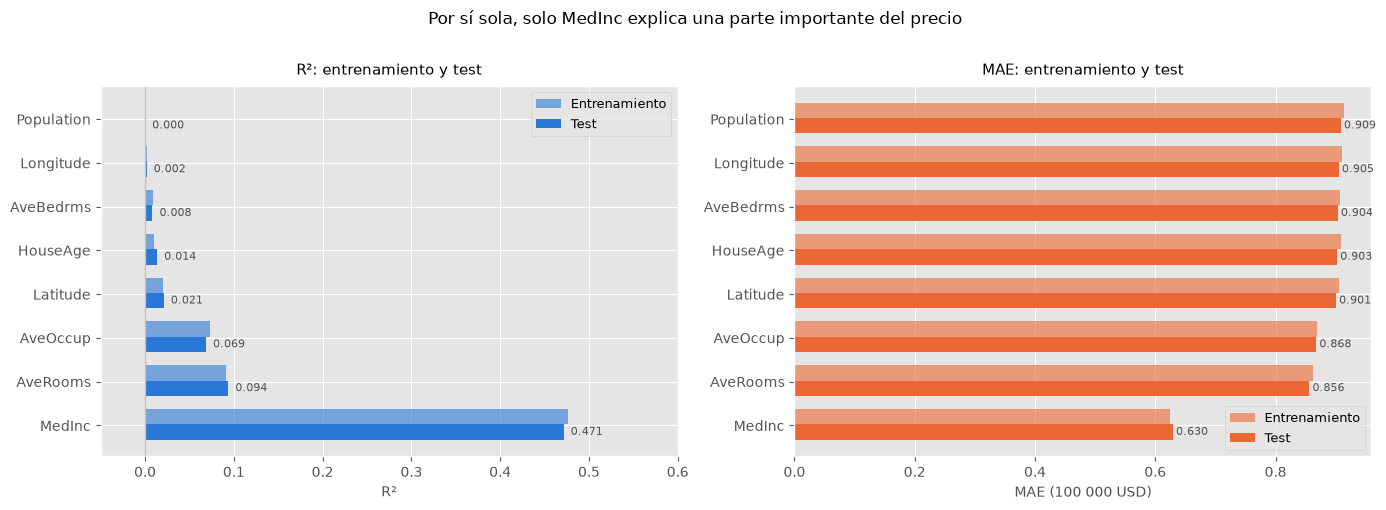

In [43]:
features_ord = df_simples.index.tolist()   # ordenadas por R² de test, de mayor a menor
y_pos = range(len(features_ord))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel izquierdo: R² en entrenamiento y test
ax = axes[0]
ax.barh([p + 0.2 for p in y_pos], df_simples['R²_train'], height=0.35, color=C1, alpha=0.6, label='Entrenamiento')
ax.barh([p - 0.15 for p in y_pos], df_simples['R²_test'], height=0.35, color=C1, alpha=1.0, label='Test')
ax.axvline(0, color='#c3c2b7', linewidth=1)
ax.set_yticks(list(y_pos))
ax.set_yticklabels(features_ord, fontsize=10)
ax.set_xlabel('R²', fontsize=10, color=CTEXT)
ax.set_title('R²: entrenamiento y test', fontsize=11, pad=8)
ax.legend(fontsize=9)
ax.set_xlim(-0.05, 0.60)
for i, feat in enumerate(features_ord):
    ax.text(df_simples.loc[feat, 'R²_test'] + 0.008, i - 0.15, f"{df_simples.loc[feat, 'R²_test']:.3f}",
            va='center', fontsize=8, color=CTEXT)

# Panel derecho: MAE en entrenamiento y test
ax = axes[1]
ax.barh([p + 0.2 for p in y_pos], df_simples['MAE_train'], height=0.35, color=C2, alpha=0.6, label='Entrenamiento')
ax.barh([p - 0.15 for p in y_pos], df_simples['MAE_test'], height=0.35, color=C2, alpha=1.0, label='Test')
ax.set_yticks(list(y_pos))
ax.set_yticklabels(features_ord, fontsize=10)
ax.set_xlabel('MAE (100 000 USD)', fontsize=10, color=CTEXT)
ax.set_title('MAE: entrenamiento y test', fontsize=11, pad=8)
ax.legend(fontsize=9)
for i, feat in enumerate(features_ord):
    ax.text(df_simples.loc[feat, 'MAE_test'] + 0.005, i - 0.15, f"{df_simples.loc[feat, 'MAE_test']:.3f}",
            va='center', fontsize=8, color=CTEXT)

plt.suptitle('Por sí sola, solo MedInc explica una parte importante del precio', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

**Observaciones**

**R² (panel izquierdo):**

- **`MedInc`** es, con diferencia, la variable más informativa por sí sola: explica un 47 % de la varianza del precio.
- Las siguientes, `AveRooms` (0,09) y `AveOccup` (0,07), explican muy poco por separado.
- **`Latitude`** y **`Longitude`** tienen un R² casi nulo (0,02 y 0,00), aunque en los gráficos de la sección 2.3 vemos que la ubicación sí importa. No es que no haya señal: es que **la señal no es lineal** y una recta no la captura.
- La diferencia entre el R² de entrenamiento y el de test es mínima en todas las variables: **no hay sobreajuste** en ningún modelo simple, lo que es esperable con una sola variable y 16.396 bloques de entrenamiento.

**MAE (panel derecho):**

- El MAE también es parecido en entrenamiento y test.
- Las variables con un R² casi nulo tienen un MAE cercano a 0,91, el de predecir siempre la media del precio: apenas aportan información.

## 6. Regresión lineal múltiple

La **regresión por mínimos cuadrados ordinarios** (OLS, *ordinary least squares*) busca los coeficientes $\beta_0, \beta_1, \ldots, \beta_p$ que minimizan la suma de los cuadrados de los residuos:

$$\boldsymbol{\hat{y}} = \beta_0 + \beta_1 \textbf{x}_1 + \cdots + \beta_p \textbf{x}_p \qquad \text{minimiza} \quad \sum_{i=1}^{n} (\textbf{y}_i - \boldsymbol{\hat{y}}_i)^2$$

Cada coeficiente $\beta_j$ es el cambio medio en `MedHouseVal` (en cientos de miles de USD) cuando $\textbf{x}_j$ aumenta **una unidad** y las demás variables no cambian.

In [44]:
model = LinearRegression()
model.fit(X_train, y_train)

print(f'Intercepto (beta_0): {model.intercept_:.4f}')
print(f'Número de coeficientes: {len(model.coef_)}')

Intercepto (beta_0): -35.1404
Número de coeficientes: 8


**Observaciones**

- `LinearRegression()` de scikit-learn resuelve el problema de mínimos cuadrados y encuentra los coeficientes $\hat{\beta}$ que minimizan la suma de los cuadrados de los residuos.
- El intercepto $\beta_0$ es el precio que predice el modelo cuando todas las variables valen 0. Aquí no tiene interpretación económica: ningún bloque tiene latitud 0, longitud 0 e ingresos 0.
- Ajustamos el modelo con las variables **en su escala original**, así que los coeficientes **no son directamente comparables** entre sí. Lo veremos en la sección 9, y en la sesión 10 aprenderemos a resolverlo con la **estandarización**.

### 6.1 Evaluación con R², MAE y RMSE

Evaluamos el modelo sobre el **conjunto de test**, con datos que no ha visto durante el entrenamiento.


| Métrica | Fórmula | Interpretación |
|---|---|---|
| **R²** | $1 - \frac{\sum(y_i-\hat{y}_i)^2}{\sum(y_i-\bar{y})^2}$ | Fracción de la varianza explicada: 1 = perfecto; 0 = no mejor que predecir siempre la media |
| **MAE** | $\frac{1}{n}\sum\lvert y_i-\hat{y}_i\rvert$ | Error medio, en las mismas unidades que la variable objetivo (100.000 USD) |
| **RMSE** | $\sqrt{\frac{1}{n}\sum(y_i-\hat{y}_i)^2}$ | Penaliza más los errores grandes; también en las unidades de la variable objetivo |


In [45]:
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'R²:   {r2:.4f}')
print(f'MAE:  {mae:.4f}  (en cientos de miles de USD: ≈ {mae * 100_000:,.0f} USD)')
print(f'RMSE: {rmse:.4f}')

R²:   0.6515
MAE:  0.4964  (en cientos de miles de USD: ≈ 49,643 USD)
RMSE: 0.6789


**Observaciones**

- **R² ≈ 0,65:** la regresión lineal explica un 65 % de la varianza del precio, bastante más que el mejor modelo simple (0,47 con `MedInc`). Para un modelo lineal sin transformaciones ni interacciones, es un punto de partida razonable.
- **MAE ≈ 50.000 USD:** el modelo se equivoca, de media, en unos 50.000 USD por bloque censal, alrededor de un 24 % del precio medio del conjunto de test (206.000 USD).
- **RMSE > MAE:** la diferencia indica que hay algunos errores grandes. Veremos dónde en las secciones 7 y 8.

**¿Qué falta para mejorar el R²?**

- Transformaciones logarítmicas de `MedInc` o `AveOccup`, que reducirían la asimetría.
- Términos de interacción (por ejemplo, `MedInc × Latitude`).
- Modelos no lineales (*random forest*, *gradient boosting*), que capturan relaciones complejas. Los veremos en el bloque de *machine learning*.

**Ejercicio 2**

a) Calcula R², MAE y RMSE en el **conjunto de entrenamiento** y compáralas con las de test. ¿Hay sobreajuste?

b) Calcula el MAE en test de un modelo que **siempre predice la media** de `y_train`. ¿Cuánto mejora nuestro modelo respecto a no usar ninguna variable?

In [46]:
# Escribe aquí tu solución

_Tu respuesta:_

### 6.2 Comprueba a la IA

Si le pides a un asistente de IA «calcula el R² del modelo en el conjunto de test», es fácil que te dé un código como este. Se ejecuta sin errores y da una cifra con buena pinta:

In [47]:
# Código como el que suele proponer un asistente de IA
r2_ia = r2_score(y_pred, y_test)
print(f'R² del modelo en test: {r2_ia:.3f}')

R² del modelo en test: 0.465


**Ejercicio 3**

a) Compara la cifra con la de la sección 6.1. ¿Por qué no coinciden?

Pista: mira el orden de los argumentos en `help(r2_score)`.

b) Calcula el R² a mano con la fórmula de la tabla de la sección 6.1 y escribe un `assert` que compruebe que coincide con `r2_score` usado correctamente.


In [48]:
# Escribe aquí tu solución

_Tu respuesta:_

## 7. Diagnóstico de residuos

Un **residuo** es la diferencia entre el valor real y el valor predicho:

$$e_i = y_i - \hat{y}_i$$

Un residuo positivo significa que el modelo **subestima** el precio; uno negativo, que lo **sobreestima**. Si el modelo es adecuado, los residuos no deberían mostrar ningún patrón.

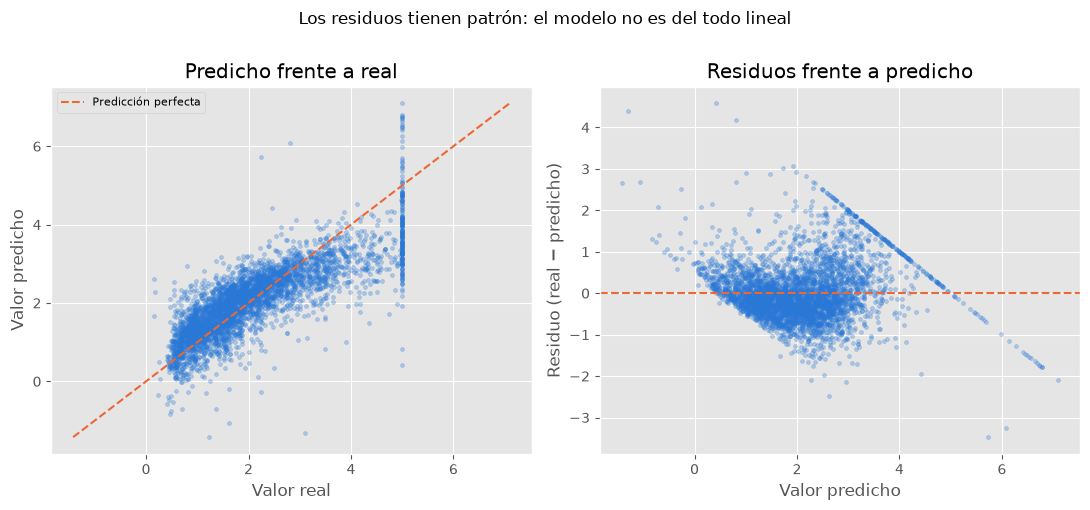

In [49]:
residuos = y_test.values - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Panel 1: predicho frente a real
ax = axes[0]
ax.scatter(y_test, y_pred, alpha=0.3, s=8, color=C1)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, '--', color=C2, linewidth=1.5, label='Predicción perfecta')
ax.set_xlabel('Valor real')
ax.set_ylabel('Valor predicho')
ax.set_title('Predicho frente a real')
ax.legend(fontsize=8)

# Panel 2: residuos frente a predicho
ax = axes[1]
ax.scatter(y_pred, residuos, alpha=0.3, s=8, color=C1)
ax.axhline(0, color=C2, linewidth=1.5, linestyle='--')
ax.set_xlabel('Valor predicho')
ax.set_ylabel('Residuo (real − predicho)')
ax.set_title('Residuos frente a predicho')

plt.suptitle('Los residuos tienen patrón: el modelo no es del todo lineal', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

**Observaciones**

**Panel 1, predicho frente a real:**

- Si el modelo fuera perfecto, todos los puntos estarían sobre la diagonal naranja.
- Hay dos desviaciones sistemáticas: con precios reales bajos, los puntos quedan por encima de la diagonal (el modelo **sobreestima**); con precios reales altos, por debajo (el modelo **subestima**).
- Los bloques censurados forman una columna vertical en el valor real 5: el modelo les predice precios muy diversos, casi siempre por debajo.
- Algunas predicciones son negativas: un modelo lineal no sabe que un precio no puede ser negativo.

**Panel 2, residuos frente a predicho:**

- Si se cumplieran los supuestos del modelo, los residuos estarían **centrados en 0 y sin ningún patrón**.
- La franja diagonal que baja hacia la derecha son, de nuevo, los bloques censurados: su residuo es 5 menos la predicción.
- La dispersión de los residuos no es constante: cambia según la predicción. Esto contradice el supuesto de **homocedasticidad** (varianza constante de los residuos).

**Conclusión:** los residuos muestran no linealidad y heterocedasticidad. Las predicciones siguen siendo útiles, pero los intervalos de confianza de los coeficientes, que suponen varianza constante, hay que tomarlos con precaución.

## 8. Error por rango de precio

Las métricas globales promedian el error. Si separamos el MAE por **deciles del precio real**, vemos en qué segmento del mercado funciona mejor y peor el modelo.

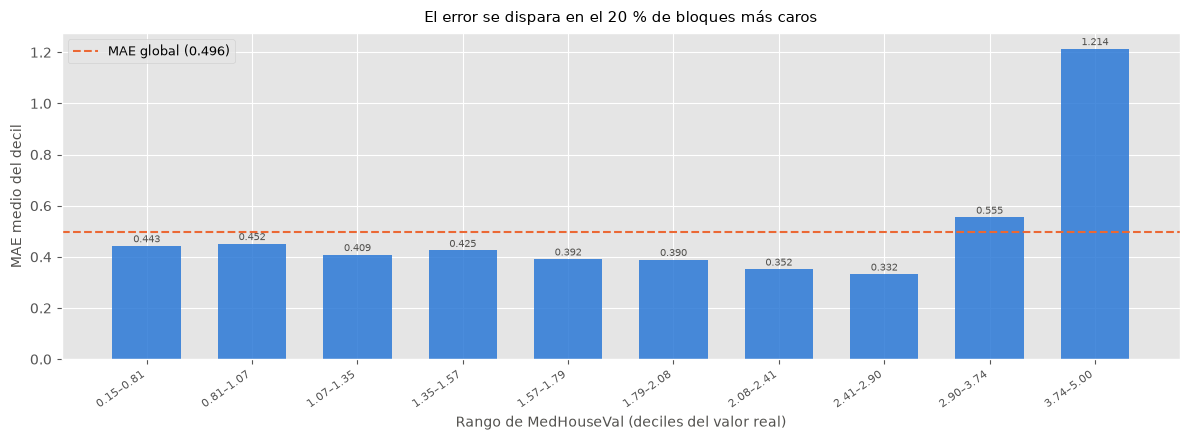

In [50]:
n_bins = 10

# Trabajamos con Series de pandas para que el indexado booleano sea consistente
y_test_s = pd.Series(y_test.values, name='y_real')
residuos_s = pd.Series(residuos, name='residuo')

bins = pd.qcut(y_test_s, q=n_bins, duplicates='drop')
categorias = bins.cat.categories
bin_labels = [f'{c.left:.2f}–{c.right:.2f}' for c in categorias]

mae_bin = [residuos_s[bins == cat].abs().mean() for cat in categorias]

fig, ax = plt.subplots(figsize=(12, 4.5))
barras = ax.bar(range(len(categorias)), mae_bin, color=C1, alpha=0.85, width=0.65)
ax.axhline(mae, color=C2, linewidth=1.5, linestyle='--', label=f'MAE global ({mae:.3f})')
for barra, val in zip(barras, mae_bin):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.004, f'{val:.3f}',
            ha='center', va='bottom', fontsize=7.5, color=CTEXT)
ax.set_xticks(range(len(categorias)))
ax.set_xticklabels(bin_labels, rotation=35, ha='right', fontsize=8)
ax.set_xlabel('Rango de MedHouseVal (deciles del valor real)', fontsize=10, color=CTEXT)
ax.set_ylabel('MAE medio del decil', fontsize=10, color=CTEXT)
ax.set_title('El error se dispara en el 20 % de bloques más caros', fontsize=11, pad=8)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Observaciones**

- El **error no es homogéneo**: el modelo no se equivoca igual en todos los segmentos del mercado.
- En los ocho primeros deciles (precio real hasta unos 290.000 USD), el MAE está entre 0,33 y 0,45, **por debajo del MAE global**.
- En los dos deciles más caros, el error se dispara: 0,56 en el noveno y 1,21 en el décimo, más del doble del MAE global. El último decil incluye los bloques censurados, con un precio real de 500.000 USD «o más» que el modelo no puede acertar.
- Este gráfico es más informativo que el MAE global para comunicar las limitaciones del modelo a quien lo vaya a usar.

**Ejercicio 4**

El MAE dice cuánto se equivoca el modelo, pero no hacia qué lado. Calcula la **media de los residuos con signo** de cada decil. ¿En qué deciles sobreestima el modelo y en cuáles subestima? ¿Coincide con lo que veías en el panel 1 de la sección 7?

In [51]:
# Escribe aquí tu solución

_Tu respuesta:_

## 9. Abrir la caja: cómo calcula el modelo una predicción

Una regresión lineal es un modelo **transparente**: la predicción de un bloque es una suma,

$$\hat{y} = \beta_0 + \beta_1 x_1 + \cdots + \beta_p x_p$$

así que cada término $\beta_j x_j$ es la **contribución** de la variable $j$ a esa predicción concreta. Empezamos por los coeficientes que ha aprendido el modelo:

In [52]:
coeficientes = pd.Series(model.coef_, index=FEATURES, name='coeficiente')
coeficientes.to_frame()

,coeficiente
MedInc,0.4291
HouseAge,0.0106
AveRooms,-0.1082
AveBedrms,0.8364
Population,0.0000
AveOccup,-0.3430
Latitude,-0.4395
Longitude,-0.4309


Ahora descomponemos la predicción del primer bloque censal del conjunto de test en la contribución (valor x coeficiente) individual de cada variable:

In [53]:
def descomponer(bloque: pd.Series) -> pd.DataFrame:
    # Contribución de cada variable a la predicción de un bloque, ordenada por tamaño ascendente de contribución absoluta
    contrib = pd.DataFrame({'valor': bloque, 'coeficiente': model.coef_, 'contribución': bloque * model.coef_})
    return contrib.reindex(contrib['contribución'].abs().sort_values(ascending=False).index)


bloque = X_test.iloc[0]
display(descomponer(bloque))
print(f'β0 + suma de contribuciones: {model.intercept_ + (bloque * model.coef_).sum():.4f}')
print(f'model.predict:               {model.predict(X_test.iloc[[0]])[0]:.4f}')
print(f'Valor real:                  {y_test.iloc[0]:.4f}')

,valor,coeficiente,contribución
Longitude,-121.3000,-0.4309,52.2734
Latitude,38.5800,-0.4395,-16.9557
MedInc,2.8966,0.4291,1.2428
AveOccup,3.0838,-0.3430,-1.0578
AveBedrms,1.0724,0.8364,0.8969
AveRooms,5.2343,-0.1082,-0.5662
HouseAge,29.0000,0.0106,0.3065
Population,1619.0000,0.0000,0.0584


β0 + suma de contribuciones: 1.0579
model.predict:               1.0579
Valor real:                  0.9240


La suma reproduce exactamente la predicción: no hay nada escondido. 

Pero fíjate en las contribuciones más grandes: la de Longitude (+52.3) es enorme comparada con la de MedInc (+1.24), aunque ambas tengan coeficientes de tamaño similar (≈ 0.43). La diferencia no viene del coeficiente sino del valor de la feature: −121 frente a 2.9. **El tamaño de una contribución depende de las unidades y del origen de cada variable**, no solo de su importancia real. El intercepto β₀ (-35) absorbe parte de ese desplazamiento, pero las contribuciones individuales de las coordenadas quedan artificialmente infladas. Para comparar importancias de forma justa necesitamos estandarizar.

Lo mismo pasa con los coeficientes. El de `Population` es 0,000036 y el de `Latitude`, −0,44. ¿Qué variable es más importante para el modelo? La respuesta no es inmediata: los coeficientes están en **unidades distintas** (personas y grados) y no son comparables. Esta pregunta queda abierta hasta la **sesión 10**, donde aprenderemos a estandarizar las variables para que todos los coeficientes hablen en la misma unidad, y veremos que esa misma estandarización es imprescindible antes de aplicar la regularización.

**Ejercicio 5**

Busca el bloque del conjunto de test con el **mayor error absoluto** y descompón su predicción con la función `descomponer`. ¿Cuál es su precio real y cuál el predicho? ¿Por qué crees que se equivoca tanto el modelo? ¿Podemos decir que la variable con la contribución más grande es la «culpable» del error?

Pista: `np.argmax(np.abs(residuos))` da la posición del bloque en `X_test`.

In [54]:
# Escribe aquí tu solución

_Tu respuesta:_

## 10. Regresión polinomial: ¿mejora el modelo?

El diagnóstico de residuos mostró que la relación entre las variables y el precio no es del todo lineal. Una **regresión polinomial** añade potencias de las variables ($x^2$, $x^3$, …) para capturar curvaturas. Lo probamos con la variable más informativa, `MedInc`. ¿Mejora el R²? ¿A qué coste?

In [55]:
feature = 'MedInc'   # la variable con mayor R² en la sección 4
X_poly_train = X_train[[feature]]
X_poly_test = X_test[[feature]]

degrees = [1, 2, 3]
r2_train_poly, r2_test_poly, models_poly = [], [], {}

for d in degrees:
    pipe = Pipeline([
        ('poly', PolynomialFeatures(degree=d, include_bias=False)),
        ('scaler', StandardScaler()),
        ('reg', LinearRegression()),
    ])
    pipe.fit(X_poly_train, y_train)
    r2_train_poly.append(pipe.score(X_poly_train, y_train))
    r2_test_poly.append(pipe.score(X_poly_test, y_test))
    models_poly[d] = pipe

print('Resumen:')
for d, tr, te in zip(degrees, r2_train_poly, r2_test_poly):
    print(f'  Grado {d}:  R² entrenamiento = {tr:.4f}  R² test = {te:.4f}  diferencia = {tr - te:.4f}')

Resumen:
  Grado 1:  R² entrenamiento = 0.4768  R² test = 0.4715  diferencia = 0.0053
  Grado 2:  R² entrenamiento = 0.4812  R² test = 0.4769  diferencia = 0.0043
  Grado 3:  R² entrenamiento = 0.4888  R² test = 0.4854  diferencia = 0.0034


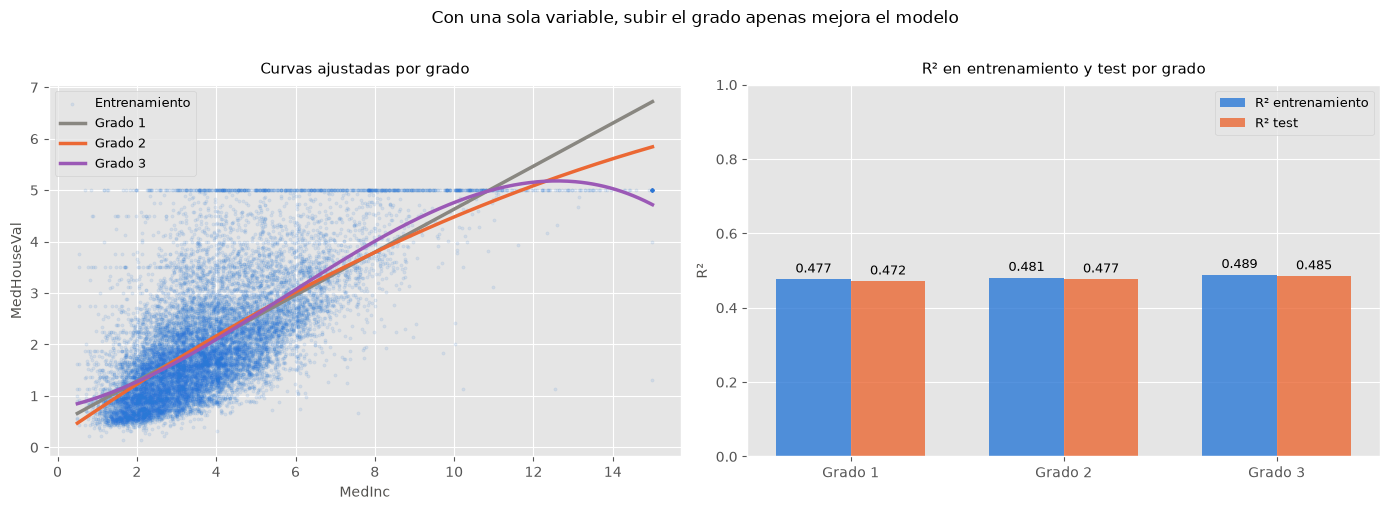

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel izquierdo: curvas ajustadas sobre los datos de entrenamiento
x_range = pd.DataFrame({feature: np.linspace(X_poly_train[feature].min(), X_poly_train[feature].max(), 300)})
axes[0].scatter(X_poly_train[feature], y_train, alpha=0.1, s=5, color=C1, label='Entrenamiento')
for d, col in zip(degrees, [C3, C2, '#9b59b6']):
    axes[0].plot(x_range[feature], models_poly[d].predict(x_range), color=col, linewidth=2.5, label=f'Grado {d}')
axes[0].set_xlabel('MedInc', fontsize=10, color=CTEXT)
axes[0].set_ylabel('MedHouseVal', fontsize=10, color=CTEXT)
axes[0].set_title('Curvas ajustadas por grado', fontsize=11, pad=8)
axes[0].legend(fontsize=9)

# Panel derecho: R² en entrenamiento y test por grado
x_ticks = np.arange(len(degrees))
width = 0.35
axes[1].bar(x_ticks - width / 2, r2_train_poly, width, label='R² entrenamiento', color=C1, alpha=0.8)
axes[1].bar(x_ticks + width / 2, r2_test_poly, width, label='R² test', color=C2, alpha=0.8)
axes[1].set_xticks(x_ticks)
axes[1].set_xticklabels([f'Grado {d}' for d in degrees])
axes[1].set_ylabel('R²', fontsize=10, color=CTEXT)
axes[1].set_title('R² en entrenamiento y test por grado', fontsize=11, pad=8)
axes[1].legend(fontsize=9)
axes[1].set_ylim(0, 1)
for i, (tr, te) in enumerate(zip(r2_train_poly, r2_test_poly)):
    axes[1].text(i - width / 2, tr + 0.01, f'{tr:.3f}', ha='center', va='bottom', fontsize=9)
    axes[1].text(i + width / 2, te + 0.01, f'{te:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Con una sola variable, subir el grado apenas mejora el modelo', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

**Observaciones**

- Subir el grado mejora el R² de test muy poco: de 0,472 (grado 1) a 0,477 (grado 2) y 0,485 (grado 3). Las curvas se separan de la recta sobre todo en los extremos de `MedInc`, donde hay pocos datos.
- La diferencia entre entrenamiento y test es mínima y **no crece** con el grado (0,005, 0,004 y 0,003): aquí **no hay sobreajuste**. Con 16.396 bloques y una sola variable, un polinomio de grado 3 (3 coeficientes) no tiene capacidad para memorizar el ruido.
- Ninguno de los modelos polinomiales se acerca al R² del modelo múltiple (0,65): la ganancia de verdad viene de **combinar variables**, no de curvar una sola.

El sobreajuste aparece cuando el modelo tiene mucha capacidad en relación con los datos: muchos coeficientes y pocos ejemplos. Lo provocas en el ejercicio siguiente.

**Ejercicio 6**

Toma una muestra de solo **30 bloques** del conjunto de entrenamiento (`X_train[['MedInc']].sample(30, random_state=SEED)` y su `y_train` correspondiente). Ajusta los polinomios de grado 1, 3 y 10 y calcula el R² en esa muestra y en todo el conjunto de test. ¿Qué ocurre al subir el grado? ¿Cómo puede salir un R² negativo?

In [57]:
# Escribe aquí tu solución

_Tu respuesta:_

## 11. Conclusiones

### Resumen

- Antes de modelar, **explora y limpia**: la censura del precio y los cocientes con denominadores pequeños son problemas que ningún modelo resuelve solo. Cada decisión de limpieza cambia el dominio en el que el modelo es válido, y hay que documentarla.
- El conjunto de test **no puede influir** en ninguna decisión de modelado.
- La regresión lineal múltiple explica un 65 % de la varianza del precio, con un error medio de unos 50.000 USD. Compárala siempre con una referencia: predecir la media o el mejor modelo simple.
- Las métricas globales esconden **dónde** falla el modelo: los residuos y el error por rango de precio muestran que sobreestima los bloques baratos y subestima mucho los caros.
- Un modelo lineal es transparente: cada predicción es una suma de contribuciones. Pero los coeficientes y las contribuciones dependen de las unidades: **no son una medida de importancia**.
- Más complejidad no siempre es mejor modelo. Con muchos datos y pocos parámetros no hay sobreajuste; con pocos datos y muchos parámetros, sí.

### Limitaciones del modelo actual

| Limitación | Causa | Solución posible |
|---|---|---|
| Coeficientes no comparables | Variables en escalas distintas | Estandarización (siguiente sesión) |
| Coeficientes inestables cuando las variables están correlacionadas | Multicolinealidad | Ridge y Lasso (siguiente sesión) |
| Error muy grande en los bloques caros | Censura del precio en 500.000 USD | Excluir los bloques censurados y documentarlo; modelos para datos censurados (Tobit) |
| Residuos con patrón | Relaciones no lineales | Transformaciones, interacciones o modelos no lineales |

### Otros pasos que se podrían explorar

1. **Agrupar la geografía** (por ejemplo, con *clustering* de las coordenadas): la latitud y la longitud no capturan la estructura de los barrios.
2. **Transformar con logaritmos la variable objetivo** (`log(MedHouseVal)`), para reducir la heterocedasticidad.
3. **Transformar con logaritmos las variables asimétricas** (`log1p(MedInc)`, `log1p(AveOccup)`).
4. **Modelos no lineales** (*random forest*, *gradient boosting*), que capturan interacciones y no linealidades.

### Para la próxima sesión

En la sesión 10 retomamos la pregunta de la sección 9: si `Population` tiene un coeficiente de 0,000036 y `Latitude`, de −0,44, ¿qué variable es más importante? Veremos que la respuesta requiere **estandarizar** las variables, y que esa estandarización es imprescindible antes de aplicar la **regularización** (Ridge y Lasso), la técnica que controla el sobreajuste que has provocado en el ejercicio 6.


## 12. Ejercicio extra: el hielo marino del Ártico

¿Ha disminuido la extensión del hielo marino del Ártico en los últimos años? Usamos las mediciones mensuales del [Centro Nacional de Datos de Nieve y Hielo](https://nsidc.org) (NSIDC) de EE. UU., de 1979 a 2014. La columna `extent` es la extensión del hielo en millones de km².

In [58]:
ice = pd.read_csv(DATOS / 'SeaIce.txt', sep=r'\s+')   # columnas separadas por espacios
print(f'Dimensiones: {ice.shape}')
ice.head()

Dimensiones: (424, 6)


,year,mo,data_type,region,extent,area
0,1979,1,Goddard,N,15.5400,12.3300
1,1980,1,Goddard,N,14.9600,11.8500
2,1981,1,Goddard,N,15.0300,11.8200
3,1982,1,Goddard,N,15.2600,12.1100
4,1983,1,Goddard,N,15.1000,11.9200


**Ejercicio 7 (opcional)**

a) **Limpia los datos.** Mira `ice.describe()`: hay meses sin medición, registrados con un código especial.

b) **Calcula la anomalía.** La extensión cambia mucho de un mes a otro (en invierno hay mucho más hielo), así que, para comparar años, a cada medición le restamos la media de su mismo mes en el periodo de referencia 1981–2010. Esa diferencia es la **anomalía**.

c) **Dibuja** la anomalía a lo largo del tiempo.

d) **Ajusta una regresión lineal simple** de la anomalía frente al tiempo. ¿Cuál es la pendiente (en millones de km² por década) y el R²?

e) **Estima** la anomalía para 2025. ¿Te fías de esa estimación? ¿Por qué?

In [59]:
# Escribe aquí tu solución

_Tu respuesta:_